1. Loading Dataset :

we import the required libraries and load the dataset. We will also establish a fixed random seed to make our experiments reproducible.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import json
from pathlib import Path

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV,
    RandomizedSearchCV
)

import os
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
RANDOM_STATE = 42

In [42]:
df = pd.read_csv(
    '../data/LLM Inference Logs & Performance Metrics/llm_inference_logs.csv'
)

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [43]:
df.head()

,timestamp,model_name,task_type,provider,prompt_tokens,completion_tokens,cache_hit_tokens,ttft_ms,tpot_ms,total_latency_ms,estimated_cost_usd,status_code
0,2026-06-01 00:02:21,claude-3-5-sonnet,Summarization,Anthropic_API,16155,795,0,83,36.30,28854,0.060879,200
1,2026-06-01 00:02:29,claude-3-5-sonnet,Summarization,Anthropic_API,8489,616,143,98,27.91,17207,0.035168,200
2,2026-06-01 00:20:19,llama-3-70b-instruct,Summarization,Together_AI,50,59,0,53,18.56,1111,0.000098,200
3,2026-06-01 00:47:39,mistral-7b-instruct,Summarization,Self_Hosted_vLLM,3633,663,0,26,11.81,7871,0.000865,200
4,2026-06-01 00:50:02,llama-3-70b-instruct,Code_Generation,Together_AI,383,1723,0,61,18.39,31818,0.001880,200


In [44]:
df["estimated_cost_usd"] = df["estimated_cost_usd"].fillna(0)

In [45]:
df.isnull().sum()

timestamp             0
model_name            0
task_type             0
provider              0
prompt_tokens         0
completion_tokens     0
cache_hit_tokens      0
ttft_ms               0
tpot_ms               0
total_latency_ms      0
estimated_cost_usd    0
status_code           0
dtype: int64

In [49]:
categorical = [
  'provider', 'task_type ',
  'model_name','timestamp '
]

2. Splitting the Dataset

In this phase of the project, we prepare our dataset for machine learning by partitioning the data into training, validation, and test subsets, while strategically handling categorical features.

we dropped categorical features because :
Standard Linear Regression models in scikit-learn require strictly numerical inputs and cannot natively interpret raw text or categorical strings (such as Model_Name, Task_Type, or Provider). While we can use one-hot encoding to preserve them, dropping categorical features and focusing exclusively on numerical features (such as token counts, TTFT, TPOT, and estimated costs) offers several key advantages for a baseline model:

    1. Simplicity & Speed: It avoids high-cardinality column explosions and simplifies the feature space.

    2. Strong Baseline Performance: Numerical metrics like Completion_Tokens and TTFT_ms capture the primary drivers of Total_Latency_ms.

    3. Clean Foundation: It establishes an immediate performance floor before testing more complex ensemble models.

In [ ]:
# 1.we Define exactly which columns to keep (Only Numerical + Target):
numerical_cols = [ 
'prompt_tokens',        
'completion_tokens',   
'cache_hit_tokens',     
'ttft_ms',              
'tpot_ms',                 
'estimated_cost_usd' , 
'status_code'   
]
target_col = 'total_latency_ms'

# we Keep only the numerical features and the target column in th dataframe:
df_subset = df[numerical_cols + [target_col]].copy()

# 2. we Apply exact 3-way split:
df_full_train, df_test = train_test_split(
    df_subset, test_size=0.2, random_state=42
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

# Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Separate features (X) and target (y):
X_train = df_train.drop(columns=[target_col])
y_train = df_train[target_col]

X_val = df_val.drop(columns=[target_col])
y_val = df_val[target_col]

X_test = df_test.drop(columns=[target_col])
y_test = df_test[target_col]

print(f'Train shape -> X_train: {X_train.shape}')  # Will be (18000, 7)
print(f'Validation shape -> X_val: {X_val.shape}')  # Will be (6000, 7)
print(f'Test shape -> X_test: {X_test.shape}')  # Will be (6000, 7)

Train shape -> X_train: (18000, 7)
Validation shape -> X_val: (6000, 7)
Test shape -> X_test: (6000, 7)


3. Build Preprocessing Pipelines

Before feeding our numerical data into machine learning models, scaling features (like token counts and milliseconds) ensures that models like Linear Regression and regularized algorithms converge properly and weight features equally

In [52]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform train, validation, and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print('Preprocessing pipeline built: Features scaled successfully.')

Preprocessing pipeline built: Features scaled successfully.


4. Train and Tune Linear Regression Model 

We train a baseline Linear Regression model using our scaled numerical features to establish our performance floor.

after that , we will evaluate each model:
When building machine learning models, the choice of evaluation metrics depends entirely on the nature of our target variable :
Our target variable, Total_Latency_ms, is a continuous numeric value measured in milliseconds. Because we are predicting an exact numerical quantity rather than a discrete class label, classification metrics like accuracy cannot be calculated.

we use the following regression metrics:

1. Root Mean Squared Error (RMSE): Penalizes larger errors heavily by squaring them before taking the square root, making it sensitive to outliers.
2. Mean Absolute Error (MAE): Measures the average magnitude of absolute errors without penalizing large outliers as heavily, providing an intuitive interpretation in milliseconds.
3. Coefficient of Determination ($R^2$): Represents the proportion of variance in the target variable that is predictable from our features, where a score of $1.0$ indicates a perfect fit

In [57]:
# 1. Train Baseline Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Evaluate Baseline
lr_preds = lr.predict(X_val_scaled)
print("--- Baseline Linear Regression Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, lr_preds)):.4f} | MAE: {mean_absolute_error(y_val, lr_preds):.4f} | R²: {r2_score(y_val, lr_preds):.4f}")

# 2. Hyperparameter Tuning: Ridge Regularization (Alpha tuning)
ridge_params = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
ridge_grid = GridSearchCV(
    Ridge(random_state=42),
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
ridge_grid.fit(X_train_scaled, y_train)

best_lr = ridge_grid.best_estimator_
print(f'Best Ridge Alpha: {ridge_grid.best_params_}')

# Evaluate Tuned Ridge Model
best_lr_preds = best_lr.predict(X_val_scaled)
print("--- Tuned Ridge Regression Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, best_lr_preds)):.4f} | MAE: {mean_absolute_error(y_val, best_lr_preds):.4f} | R²: {r2_score(y_val, best_lr_preds):.4f}\n")

--- Baseline Linear Regression Validation ---
RMSE: 2455.9932 | MAE: 1668.5438 | R²: 0.9357
Best Ridge Alpha: {'alpha': 0.01}
--- Tuned Ridge Regression Validation ---
RMSE: 2455.9933 | MAE: 1668.5435 | R²: 0.9357



5. Training And Tuning of Decision Tree Model

Decision Trees split the feature space into hierarchical rules, allowing them to capture non-linear patterns. However, unconstrained trees quickly overfit. We use grid search to tune depth and split criteria, tracking validation RMSE, MAE, and $R^2$.

In [59]:
# 1. Train Decision Tree Base
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

dt_preds = dt.predict(X_val)
print("--- Baseline Decision Tree Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, dt_preds)):.4f} | MAE: {mean_absolute_error(y_val, dt_preds):.4f} | R²: {r2_score(y_val, dt_preds):.4f}")

# 2. Hyperparameter Tuning
dt_params = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 20],
}
dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    dt_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
dt_grid.fit(X_train, y_train)

best_dt = dt_grid.best_estimator_
print(f'Best Decision Tree Params: {dt_grid.best_params_}')

# Evaluate Tuned Decision Tree
best_dt_preds = best_dt.predict(X_val)
print("--- Tuned Decision Tree Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, best_dt_preds)):.4f} | MAE: {mean_absolute_error(y_val, best_dt_preds):.4f} | R²: {r2_score(y_val, best_dt_preds):.4f}\n")

--- Baseline Decision Tree Validation ---
RMSE: 457.5062 | MAE: 182.3658 | R²: 0.9978
Best Decision Tree Params: {'max_depth': None, 'min_samples_split': 5}
--- Tuned Decision Tree Validation ---
RMSE: 489.2560 | MAE: 184.7259 | R²: 0.9974



6. Training And Tuniing of Random Forest Model 

Random Forest is an ensemble method that builds multiple decision trees on bootstrapped subsets and averages their predictions to reduce variance. We optimize its hyperparameters and evaluate its performance metrics.

In [61]:
# 1. Train Random Forest Base
rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_preds = rf.predict(X_val)
print("--- Baseline Random Forest Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, rf_preds)):.4f} | MAE: {mean_absolute_error(y_val, rf_preds):.4f} | R²: {r2_score(y_val, rf_preds):.4f}")

# 2. Hyperparameter Tuning
rf_params = {'n_estimators': [50, 100, 150], 'max_depth': [10, 20, None]}
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
print(f'Best Random Forest Params: {rf_grid.best_params_}')

# Evaluate Tuned Random Forest
best_rf_preds = best_rf.predict(X_val)
print("--- Tuned Random Forest Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, best_rf_preds)):.4f} | MAE: {mean_absolute_error(y_val, best_rf_preds):.4f} | R²: {r2_score(y_val, best_rf_preds):.4f}\n")

--- Baseline Random Forest Validation ---
RMSE: 376.0085 | MAE: 83.4486 | R²: 0.9985


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Random Forest Params: {'max_depth': 20, 'n_estimators': 150}
--- Tuned Random Forest Validation ---
RMSE: 377.8264 | MAE: 83.3546 | R²: 0.9985



7. Training And Tuning of XGBoost Model

XGBoost (Extreme Gradient Boosting) is an industry-standard, highly optimized gradient boosting library. It builds decision trees sequentially to minimize residuals while utilizing advanced regularization (L1/L2) and parallelization to prevent overfitting and maximize performance.

In [63]:
# 1. Train Baseline XGBoost Model
xgb_base = XGBRegressor(random_state=42, n_jobs=-1)
xgb_base.fit(X_train, y_train)

xgb_preds = xgb_base.predict(X_val)
print("--- Baseline XGBoost Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, xgb_preds)):.4f} | MAE: {mean_absolute_error(y_val, xgb_preds):.4f} | R²: {r2_score(y_val, xgb_preds):.4f}")

# 2. Hyperparameter Tuning using GridSearchCV
xgb_params = {
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'n_estimators': [100, 150]
}

xgb_grid = GridSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    xgb_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
xgb_grid.fit(X_train, y_train)

best_xgb = xgb_grid.best_estimator_
print(f'Best XGBoost Params: {xgb_grid.best_params_}')

# 3. Evaluate Tuned XGBoost Model
best_xgb_preds = best_xgb.predict(X_val)
print("--- Tuned XGBoost Validation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, best_xgb_preds)):.4f} | MAE: {mean_absolute_error(y_val, best_xgb_preds):.4f} | R²: {r2_score(y_val, best_xgb_preds):.4f}\n")

--- Baseline XGBoost Validation ---
RMSE: 429.1252 | MAE: 160.9200 | R²: 0.9980
Best XGBoost Params: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 150}
--- Tuned XGBoost Validation ---
RMSE: 405.8520 | MAE: 110.5315 | R²: 0.9982



8. Compare Models On The Test Set

To know which model works best in production, we evaluate all four tuned models against an entirely unseen Test Set (data held out from both training and hyperparameter tuning). We compare them using three core regression metrics:

Test RMSE (Root Mean Squared Error): Penalizes larger prediction errors heavily.Test MAE (Mean Absolute Error): Reflects the average magnitude of error in milliseconds.Test $R^2$ (Coefficient of Determination): Measures the proportion of variance explained by the model.The model with the lowest test RMSE and highest $R^2$ is crowned the overall winner.

In [67]:
# Map each tuned model to its respective test features (using 'XGBoost' explicitly)
models_to_evaluate = {
    'Linear Regression (Ridge)': (best_lr, X_test_scaled),
    'Decision Tree': (best_dt, X_test),
    'Random Forest': (best_rf, X_test),
    'XGBoost': (
        best_xgb,
        X_test,
    ),  # Explicitly points to your trained XGBRegressor object
}

test_results = []

for name, (model, X_t) in models_to_evaluate.items():
  preds = model.predict(X_t)
  rmse = np.sqrt(mean_squared_error(y_test, preds))
  mae = mean_absolute_error(y_test, preds)
  r2 = r2_score(y_test, preds)

  test_results.append({
      'Model': name,
      'Test RMSE (ms)': rmse,
      'Test MAE (ms)': mae,
      'Test R²': r2,
  })

# Compile into a comparison dataframe sorted by RMSE
comparison_df = pd.DataFrame(test_results).sort_values(
    by='Test RMSE (ms)', ascending=True
)
print('--- Final Model Comparison on Unseen Test Set ---')
print(comparison_df.to_string(index=False))

# Identify the champion model
best_row = comparison_df.iloc[0]
best_model_name = best_row['Model']
best_model_obj, best_test_X = models_to_evaluate[best_model_name]

print(
    f'\n Overall Winning Model: {best_model_name} with Test RMSE ='
    f' {best_row["Test RMSE (ms)"]:.4f}'
)

--- Final Model Comparison on Unseen Test Set ---
                    Model  Test RMSE (ms)  Test MAE (ms)  Test R²
            Random Forest      161.284238      79.214758 0.999706
                  XGBoost      235.268223     108.033394 0.999375
            Decision Tree      363.349913     183.207500 0.998510
Linear Regression (Ridge)     2434.616324    1665.799998 0.933115

 Overall Winning Model: Random Forest with Test RMSE = 161.2842


The Important Point : 

these results show that the Nature of the Relationship is Non-Linear!
Linear Regression assumes a strictly straight-line (linear) relationship between your input features (like token counts, ttft, and tpot) and the target (total_latency_ms).
In real-world LLM inference, the relationship between generation parameters and latency is often non-linear or piecewise. For instance, factors like token generation speed (tpot_ms) interact multiplicatively with completion_tokens.
so the linear regression cannot capture these complex multiplicative interactions.

9. Saving the Best Model

We serialize and store the winning model artifact using joblib inside the models/ directory so it can be containerized and deployed via FastAPI.

In [69]:
# Create models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)
model_path = '../models/best_latency_model.joblib'

# Save the winning model object
joblib.dump(best_model_obj, model_path)
print(f'Successfully serialized and saved {best_model_name} to {model_path}')

Successfully serialized and saved Random Forest to ../models/best_latency_model.joblib


10. Feature Importances Analysis

To understand what drives LLM inference latency most, we extract feature importances from our winning tree-based model and visualize them.

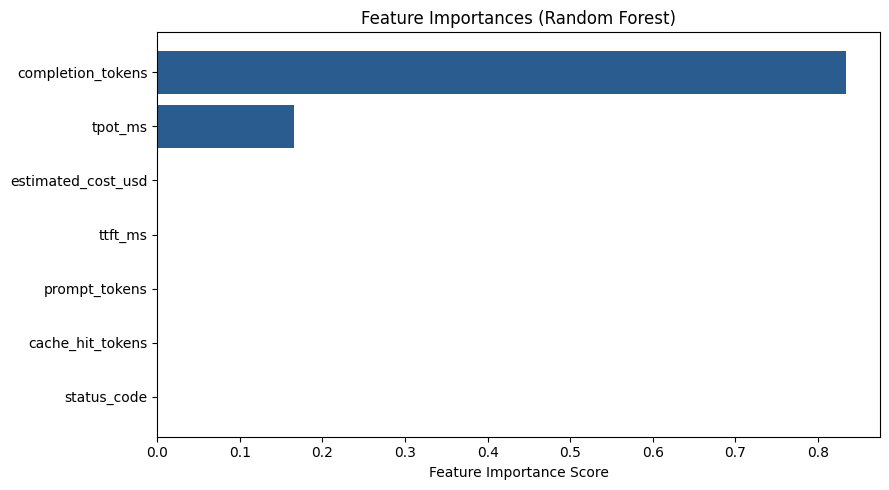


Feature Importance Breakdown:
           Feature   Importance
       status_code 4.621679e-07
  cache_hit_tokens 1.380044e-05
     prompt_tokens 9.586934e-05
           ttft_ms 1.114664e-04
estimated_cost_usd 1.521994e-04
           tpot_ms 1.661181e-01
 completion_tokens 8.335081e-01


In [71]:
# Extract feature importances
if hasattr(best_model_obj, 'feature_importances_'):
  importances = best_model_obj.feature_importances_
  feature_names = X_train.columns

  importance_df = pd.DataFrame(
      {'Feature': feature_names, 'Importance': importances}
  ).sort_values(by='Importance', ascending=True)

  # Plot feature importances
  plt.figure(figsize=(9, 5))
  plt.barh(
      importance_df['Feature'], importance_df['Importance'], color='#2b5c8f'
  )
  plt.xlabel('Feature Importance Score')
  plt.title(f'Feature Importances ({best_model_name})')
  plt.tight_layout()

  os.makedirs('../screenshots', exist_ok=True)
  plt.savefig('../screenshots/feature_importances.png')
  plt.show()

  print('\nFeature Importance Breakdown:')
  print(importance_df.to_string(index=False))